# Algorytm EM

## 1. Przykład z prostym rozkładem danych
1. Zmienna A jest rodzicem zmiennej B
2. A przyjmuje wartości a0 lub a1,  B przyjmuje X lub y
3. $P(B=x \mid A=a0) = 1$ i $P(B=y \mid A=a1) = 1$
4. Dane zawierają dwa braki

**Dodatkowo**: Sanity Check algorytmu

In [1]:
import numpy as np
import pandas as pd

from BayesianNetwork.models.data import Data, DataPurpose
from BayesianNetwork.algorithms.em_cdps_estimation import learn_cpds_em

toy_data = Data(
    DataPurpose.Train,
    pd.DataFrame({
        "A": ["a0"] * 6 + ["a1"] * 6,
        "B": [
            "x", "x", "x", "x", "x", None,  # A=a0
            "y", "y", "y", "y", None, "y",  # A=a1
        ],
    }),
)

print("Dane z rozkładu A i B")
print(toy_data.data_frame)
print()
print()

parents = {"A": [], "B": ["A"]}
cpds, hist = learn_cpds_em(toy_data, parents, seed=0)

print("Rozkłady wyliczone przez Algorytm EM")
for cpd in cpds:
    print(cpd)

Dane z rozkładu A i B
     A    B
0   a0    x
1   a0    x
2   a0    x
3   a0    x
4   a0    x
5   a0  NaN
6   a1    y
7   a1    y
8   a1    y
9   a1    y
10  a1  NaN
11  a1    y


Rozkłady wyliczone przez Algorytm EM
+-------+-----+
| A(a0) | 0.5 |
+-------+-----+
| A(a1) | 0.5 |
+-------+-----+
+------+-----------------------+-----------------------+
| A    | A(a0)                 | A(a1)                 |
+------+-----------------------+-----------------------+
| B(x) | 0.999999992681251     | 1.486727707911882e-08 |
+------+-----------------------+-----------------------+
| B(y) | 7.318749021383662e-09 | 0.9999999851327229    |
+------+-----------------------+-----------------------+


### Wynik
Log wiarygodności

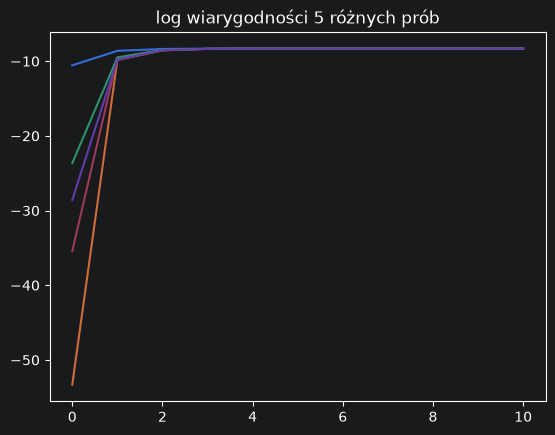

In [2]:
from matplotlib import pyplot as plt

for run in hist:
    plt.plot(run)


plt.title("log wiarygodności 5 różnych prób")
plt.show()

## 2. Przykład z Repozytorium k12

In [3]:
import os
from BayesianNetwork.parsing.description_parsing import description_parser
from BayesianNetwork.parsing.data_parsing import parse_data

data_path = os.path.join("..", "data", "zestawy", "k12")
graph = description_parser(os.path.join(data_path, "opis.json"))

variables = graph.variables_dict
data = parse_data(os.path.join(data_path, "dane.csv"), variables ,is_train_data=True)

parents = {var : [] for var in variables.keys()}
for parent, child in graph.exper_edges:
    parents[child].append(parent)

cdps, history = learn_cpds_em(data, parents, seed=42)

/tmp/ipykernel_27096/3097529537.py:9: UserWarning: Train data contains 4740 nans
  data = parse_data(os.path.join(data_path, "dane.csv"), variables ,is_train_data=True)


In [4]:
for cdp in cdps:
    print(cdp)
    print()

+---------+---------------------+--------------------+
| I       | I(Dumb)             | I(Intelligent)     |
+---------+---------------------+--------------------+
| D(Easy) | 0.6913344855298703  | 0.1733651162718425 |
+---------+---------------------+--------------------+
| D(Hard) | 0.30866551447012963 | 0.8266348837281575 |
+---------+---------------------+--------------------+

+----------------+---------+
| I(Dumb)        | 0.70249 |
+----------------+---------+
| I(Intelligent) | 0.29751 |
+----------------+---------+

+---------+----------+
| M(High) | 0.591517 |
+---------+----------+
| M(Low)  | 0.408483 |
+---------+----------+

+--------+----------+
| W(No)  | 0.589294 |
+--------+----------+
| W(Yes) | 0.410706 |
+--------+----------+

+-----------+----------------------+-----+---------------------+
| D         | D(Easy)              | ... | D(Hard)             |
+-----------+----------------------+-----+---------------------+
| W         | W(No)                | ... | W(Y

### Log Wiarygodności

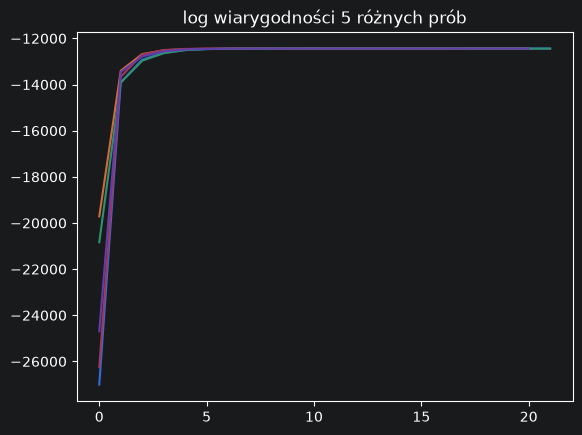

In [11]:
for run in history:
    plt.plot(np.arange(len(run)), run)


plt.title(f"log wiarygodności {len(hist)} różnych prób")
plt.show()

### Zestawienie z estymacją z Pgmpy

In [6]:
from BayesianNetwork.network.MyNetworkClass import MyNetworkClass

network_obj = MyNetworkClass.build_from_expert_graph(
    graph = graph,
    training_data = data
)

cdps_network = network_obj.network.get_cpds()


def sort_key(x):
    return x.values.shape

diffs = []
for cdp_em, cdp_net in zip(sorted(cdps, key=sort_key), sorted(cdps_network, key=sort_key)):
    print(cdp_em)
    print(cdp_net)
    print()

    diff =np.sum((cdp_em.values - cdp_net.values)**2)
    diffs.append(diff)


/home/kendama/Projects/University_Classes/SEM_5/IFM_konwoledge_enginnering/.venv/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


+----------------+---------+
| I(Dumb)        | 0.70249 |
+----------------+---------+
| I(Intelligent) | 0.29751 |
+----------------+---------+
+----------------+----------+
| I(Dumb)        | 0.714859 |
+----------------+----------+
| I(Intelligent) | 0.285141 |
+----------------+----------+

+---------+----------+
| M(High) | 0.591517 |
+---------+----------+
| M(Low)  | 0.408483 |
+---------+----------+
+---------+----------+
| M(Low)  | 0.405523 |
+---------+----------+
| M(High) | 0.594477 |
+---------+----------+

+--------+----------+
| W(No)  | 0.589294 |
+--------+----------+
| W(Yes) | 0.410706 |
+--------+----------+
+--------+----------+
| W(No)  | 0.589313 |
+--------+----------+
| W(Yes) | 0.410687 |
+--------+----------+

+---------+---------------------+--------------------+
| I       | I(Dumb)             | I(Intelligent)     |
+---------+---------------------+--------------------+
| D(Easy) | 0.6913344855298703  | 0.1733651162718425 |
+---------+---------------------

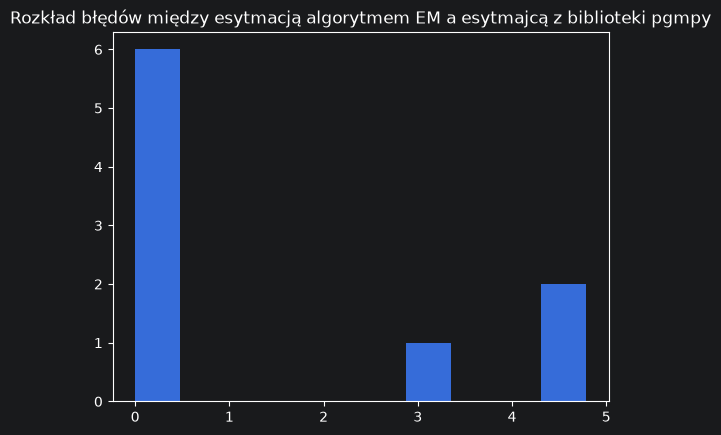

In [7]:
diffs = np.array(diffs)
plt.hist(diffs)
plt.title("Rozkład błędów między esytmacją algorytmem EM a esytmajcą z biblioteki pgmpy")
plt.show()